# DNA walker

[← All examples](../paper_examples.ipynb) · [Python analysis](../../tutorials/dna_walker_inspection.py) · [Model inputs](../../src/mfobs/models/dna_walker/inputs.py)

Four graph rules yield equations for the extended and compressed walker configurations.


<nav class="example-sections" aria-label="Example sections" style="display:flex;align-items:stretch;gap:5px;flex-wrap:wrap;margin:16px auto;padding-top:8px;padding-bottom:8px;border-bottom:1px solid #cddce1"><span data-topic="rules" style="background:#e7f3e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=b3851f86" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">1 · Rules &amp; state space</a></span><span data-topic="inputs" style="background:#fbe9e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=ea0c2cbd" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">2 · Inputs &amp; semantics</a></span><span data-topic="observables" style="background:#e8f0fb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=38cc3203" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">3 · Observable discovery</a></span><span data-topic="ode" style="background:#f0eafb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap">4 · <a href="#cell-id=353bc341" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">ODE</a> &amp; <span aria-disabled="true" title="Not analysed" style="color:#737d83;display:inline-block;vertical-align:top">pJC<small style="display:block;font-size:10px;font-weight:400">Not analysed</small></span></span><span data-topic="initial" style="background:#e3f3f0;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=54b0cb48" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">5 · Initial states</a></span><span data-topic="dynamics" style="background:#fff0de;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=bd277add" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">6 · Dynamics</a></span></nav>

In [1]:
from pathlib import Path
import sys
PACKAGE = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/mfobs').is_dir()))
NOTEBOOKS = PACKAGE / 'notebooks'
sys.path[:0] = [str(NOTEBOOKS), str(PACKAGE / 'src'), str(PACKAGE)]
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
from IPython.display import display, Math
import visual_view as visual
import visual_suite as suite

<h2 id="rules" style="background:#e7f3e9;padding:12px 16px;border-radius:5px">1 · Rules & state space</h2>

One two-legged walker on a directed cycle of length ≥5. The legs attach to one site (compressed) or adjacent sites (extended). Auxiliary edge vertices with `src`/`tgt` links encode direction and distinguish the two legs.


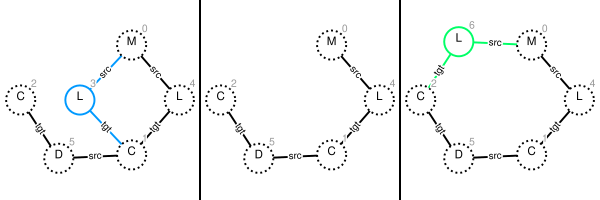

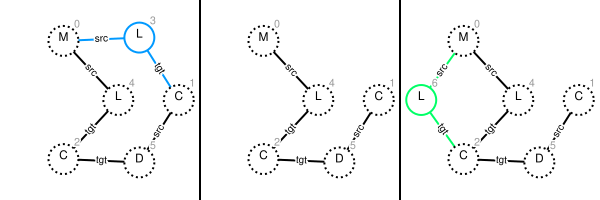

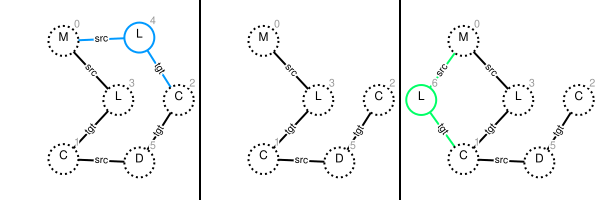

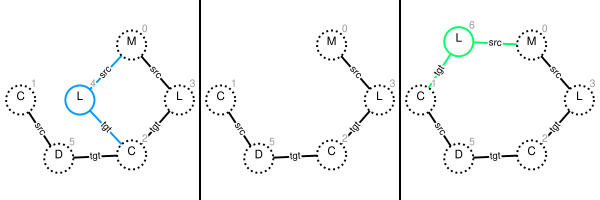

In [2]:
from mfobs import analyze
from mfobs.applications import DNAWalker
backend = DNAWalker()
defaults = backend.specification()
Omega = defaults.omega
rules = defaults.rules
observables = defaults.observables
from mfobs import ModelInputs
inputs = ModelInputs(Omega, rules, observables)
visual.rules(list(inputs.rule_gmls().items()))

Model: Danos et al., *Rate Equations for Graphs*, CMSB 2020, §1.1.


<h2 id="inputs" style="background:#fbe9e9;padding:12px 16px;border-radius:5px">2 · Inputs & semantics</h2>

The input query E counts extended configurations.


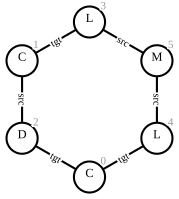

In [3]:
visual.rules(list(inputs.query_gmls().items()), identity=True)

<h2 id="observables" style="background:#e8f0fb;padding:12px 16px;border-radius:5px">3 · Observable discovery</h2>

A short scaffold path extends uniquely from its leg attachments. The reducer uses this property to identify equivalent counts. The discovered coordinate O1 counts compressed configurations twice, once for each permutation of the two legs.


Closure: CLOSED
Discovered basis: ['E', 'O1']


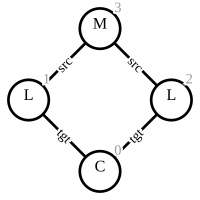

In [4]:
record = analyze(inputs, backend=backend).record()
print("Closure:", record["status"])
print("Discovered basis:", list(record["basis"]))
visual.rules([
    (name + " · " + record["display_names"][name],
     record["patterns"][next(iter(expression))])
    for name, expression in record["basis"].items() if name != "E"
], identity=True)


<h2 id="ode" style="background:#f0eafb;padding:12px 16px;border-radius:5px">4 · ODE</h2>

Normalize the compressed count by two, then compute the stationary probabilities and mean velocity.


In [5]:
import sympy as sp
symbols = {n: sp.Symbol(n) for n in ("E", "C", "kFE", "kBE", "kFC", "kBC")}
comparison = record["comparison"]
for name, expression in comparison["physical_equations"].items():
    display(Math(r"\frac{d}{dt}\mathbb{E}[" + name + "] = " + sp.latex(sp.sympify(expression, locals=symbols))))
stationary = {symbols[n]: sp.sympify(value, locals=symbols)
              for n,value in comparison["stationary_probabilities"].items()}
velocity = sum(sp.Rational(row["displacement"]) * symbols[rate] * symbols[row["normalized_activity"]]
               for rate,row in comparison["movement_readout_from_rules"].items())
stationary_velocity = sp.factor(velocity.subs(stationary))
display(Math("v_{stationary} = " + sp.latex(stationary_velocity)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<h2 id="initial" style="background:#e3f3f0;padding:12px 16px;border-radius:5px">5 · Initial states</h2>

One extended walker; probability E=1, C=0.

In [6]:
initial = {"E": 1., "C": 0.}
visual.table([initial])

,E,C
0,1.0,0.0


<h2 id="dynamics" style="background:#fff0de;padding:12px 16px;border-radius:5px">6 · Dynamics</h2>

Integrate the computed two-dimensional equations. Counts are normalized to configuration probabilities: C = Craw/2.

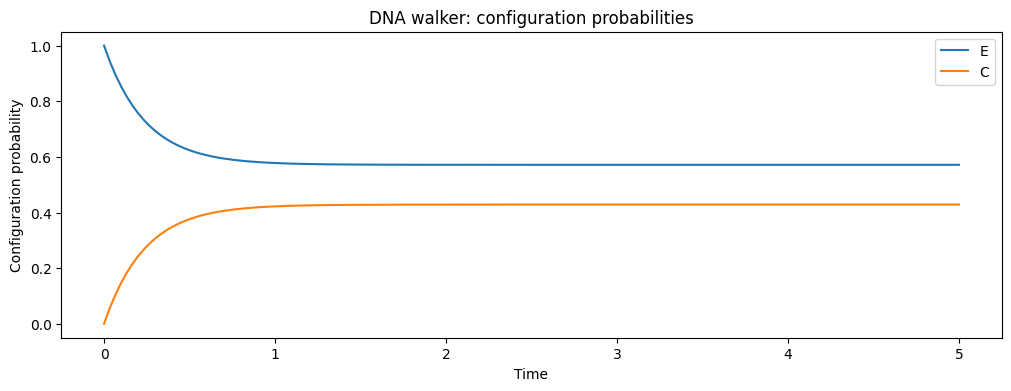

VBox(children=(FloatSlider(value=2.0, continuous_update=False, description='kFE', max=6.0, step=0.05), FloatSl…

In [7]:
T = 5.0
rates = {'kFE': 2.0, 'kBE': 0.4, 'kFC': 1.5, 'kBC': 0.3}
curves = suite.walker_curve(record, rates, end=T, initial=initial)
controls = suite.rate_controls(
    lambda rates, **opts: suite.walker_curve(record, rates, **opts), rates, {'end': T, 'initial': initial})

[← All examples](../paper_examples.ipynb)